In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [2]:
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": "serif",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 12,
    "font.size": 12,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
}
plt.rcParams.update(tex_fonts)

## Mises Distribution Function
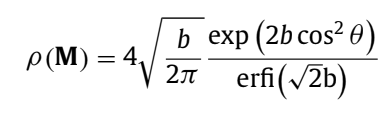

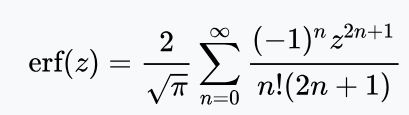

In [7]:
def erfi(x, nterm = 60):
    aux = 0.0
    for n in range(nterm):
        num = x**(2*n+1)
        den = math.factorial(n) * (2*n + 1)
        aux += num/den
    return 2 / np.sqrt(np.pi) * aux

def rho_mises(b, theta):
    num = np.exp(2 * b * np.cos(theta)**2)
    den = erfi(np.sqrt(2*b))
    return 4 * np.sqrt(b/(2*np.pi)) * num / den

theta = np.linspace(-np.pi/2, np.pi/2, 10)
b_values = [0.1, 1, 2, 5]

rho_values = [rho_mises(b, theta) for b in b_values]

print("Rho values for different b values:")
for i, b in enumerate(b_values):
    print(f"b = {b}: {rho_values[i]}")

Rho values for different b values:
b = 0.1: [0.9338247  0.95592962 1.01426949 1.08494951 1.13371825 1.13371825
 1.08494951 1.01426949 0.95592962 0.9338247 ]
b = 1: [0.42293064 0.53441022 0.96638279 1.89544363 2.94216451 2.94216451
 1.89544363 0.96638279 0.53441022 0.42293064]
b = 2: [0.12156113 0.19409124 0.63467998 2.44162054 5.88288457 5.88288457
 2.44162054 0.63467998 0.19409124 0.12156113]
b = 5: [8.55995483e-04 2.75739834e-03 5.33177306e-02 1.54767614e+00
 1.39463475e+01 1.39463475e+01 1.54767614e+00 5.33177306e-02
 2.75739834e-03 8.55995483e-04]


b=0.1
b=2
b=5


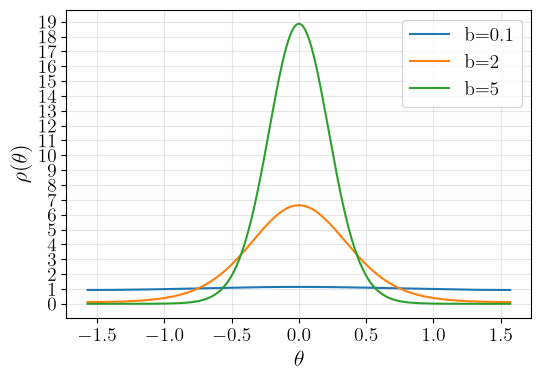

In [5]:
# Plotting
plt.figure(figsize=(6, 4))
for b, rho in zip(b_values, rho_values):
    print(f"b={b}")
    plt.plot(theta, rho, label=f'b={b}')
    # plt.plot(theta, rho/(4*np.pi), label=f'b={b}')
# plt.title('Mises Distribution Function')
plt.xlabel('$\\theta$', fontsize=16)
plt.ylabel('$\\rho(\\theta)$', fontsize=16)
plt.legend(fontsize=14)
plt.tick_params(axis='x', labelsize=14)  # Increase x-axis tick label font size
plt.tick_params(axis='y', labelsize=14)
plt.yticks(np.arange(0, 20., 1.))  # Increase y-axis tick label font size
plt.grid(alpha=0.3)
# plt.savefig('report/figures/mises_distribution.pdf', bbox_inches='tight')
# plt.show()

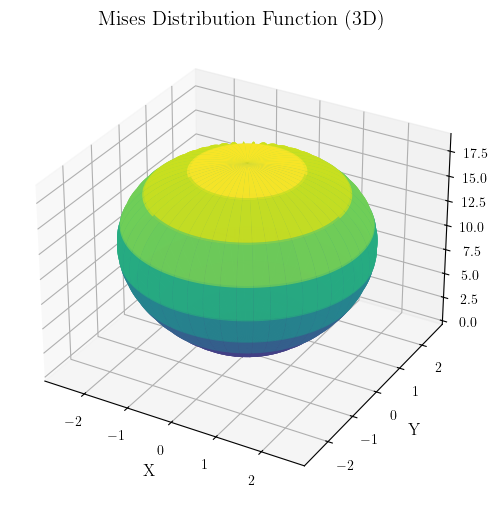

In [ ]:
# Plot a 3d figure using mplot3d
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
theta = np.linspace(-np.pi/2, np.pi/2, 1000)
phi = np.linspace(0, 2*np.pi, 1000)
theta, phi = np.meshgrid(theta, phi)
b = 5
rho = rho_mises(b, theta)
x = rho * np.cos(phi) * np.sin(theta)
y = rho * np.sin(phi) * np.sin(theta)
z = rho * np.cos(theta) 
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, cmap=cm.viridis, alpha=0.8)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Mises Distribution Function (3D)')
plt.show()
